## Camden Goering (cgoering) - MiniProject1 Goals

### Question
How consistent is an author's word usage across their own books, compared to how different two separate authors sound from each other?

### Approach
1. **Same-author comparison:** Mark Twain's *The Adventures of Huckleberry Finn* vs. *The Adventures of Tom Sawyer* -- both set in the same world with overlapping characters, so this isolates Twain's own stylistic fingerprint.
2. **Cross-author comparison:** Mark Twain vs. Jack London's *The Call of the Wild* -- both adventure fiction from a similar era, so differences should reflect authorial style rather than just genre or subject matter.
3. Compute word frequency distributions for each text (excluding stop words), compare the top frequent words across the three texts, and identify words one author favors that the other rarely uses.

### Data Sources
- *The Adventures of Huckleberry Finn* -- Project Gutenberg, https://www.gutenberg.org/ebooks/76.txt.utf-8
- *The Adventures of Tom Sawyer* -- Project Gutenberg, https://www.gutenberg.org/ebooks/74.txt.utf-8
- *The Call of the Wild* -- Project Gutenberg, https://www.gutenberg.org/ebooks/215.txt.utf-8

### Stretch Goal
If time allows, model the frequency of a specific shared word (e.g. "said") as a binomial distribution and compare it across the three texts, per the extra-credit prompt.

# Assignment 1

1. Compare word frequencies between two works of a single author.
1. Compare word frequencies between works of two authors.
1. Are there some words preferred by one author but used less frequently by another author?

Extra credit

1. The frequency of a specific word, e.g., "would" should follow a binomial distribution (each regular word in a document is a trial and with probability p that word is "would". The estimate for p is N("would")/N(regular word)). Do these binomial distributions for your chosen word differ significantly between books of the same author or between authors? 

Project Gutenberg is a good source of for fiction and non-fiction.

E.g below are two most popular books from Project Gutenberg:
- Pride and Prejudice at http://www.gutenberg.org/ebooks/1342.txt.utf-8
- Adventures of Huckleberry Finn at http://www.gutenberg.org/ebooks/76.txt.utf-8

## My Analysis

Same-author: *Huckleberry Finn* vs *Tom Sawyer* (both Twain). Cross-author: Twain vs Jack London's *The Call of the Wild*.

This reuses the same word-frequency idea as the demo above, but adapted for plain-text Gutenberg files instead of an HTML page: strip the Gutenberg header/footer boilerplate, lowercase, split into words, strip punctuation, and drop stop words.

In [1]:
import requests, re, nltk
from collections import Counter
import operator

nltk.download('stopwords')

stop_words = set(nltk.corpus.stopwords.words('english') + [
    'ut', "'re", '.', ',', '--', "'s", '?', ')', '(', ':', "'",
    '"', '-', '}', '{', '&', '|', u'\u2014', '', "'d", "'ll", "'m", "'ve"
])

def strip_gutenberg_boilerplate(text):
    # Gutenberg wraps the actual book text between these markers
    start_match = re.search(r'\*\*\* START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*', text, re.IGNORECASE)
    end_match = re.search(r'\*\*\* END OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*', text, re.IGNORECASE)
    start = start_match.end() if start_match else 0
    end = end_match.start() if end_match else len(text)
    return text[start:end]

def clean_word(w):
    # strip punctuation stuck to the edges/inside of a word
    wn = re.sub(r'[,"\.\'&\|:@>*;/=_\[\]]', "", w)
    # drop pure numbers
    return re.sub(r'^[0-9\.]*$', "", wn)

def get_word_freq(url):
    r = requests.get(url)
    t = strip_gutenberg_boilerplate(r.text).lower()
    wds = re.split(r'\s+', t)
    wds = [clean_word(w) for w in wds]
    wds = [w for w in wds if w]  # drop anything that cleaned down to empty

    wf = Counter(wds)
    for k in stop_words:
        wf.pop(k, None)

    # return both the cleaned word-frequency dict (stop words removed, for display/plots)
    # and the raw word list (stop words included, for total counts / binomial estimate)
    return wf, wds

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\camgo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
huck_url = 'https://www.gutenberg.org/ebooks/76.txt.utf-8'   # Huckleberry Finn (Twain)
tom_url  = 'https://www.gutenberg.org/ebooks/74.txt.utf-8'    # Tom Sawyer (Twain)
wild_url = 'https://www.gutenberg.org/ebooks/215.txt.utf-8'   # The Call of the Wild (London)

wf_huck, words_huck = get_word_freq(huck_url)
wf_tom,  words_tom  = get_word_freq(tom_url)
wf_wild, words_wild = get_word_freq(wild_url)

print('Huckleberry Finn total words:', len(words_huck))
print('Tom Sawyer total words:', len(words_tom))
print('Call of the Wild total words:', len(words_wild))

Huckleberry Finn total words: 111075
Tom Sawyer total words: 70785
Call of the Wild total words: 31823


In [3]:
def top_n(wf, n=15):
    return sorted(wf.items(), key=operator.itemgetter(1), reverse=True)[:n]

top_huck = top_n(wf_huck)
top_tom  = top_n(wf_tom)
top_wild = top_n(wf_wild)

print('Top words -- Huck Finn:')
for w, c in top_huck: print(f'{w}\t{c}')

Top words -- Huck Finn:
says	637
got	622
said	474
see	468
would	402
come	375
one	366
didn’t	336
get	332
don’t	309
could	303
jim	302
time	296
went	294
warn’t	292


### Same-author comparison: Huck Finn vs Tom Sawyer

Reusing the `plotTwoLists` function already defined above in the demo.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

def plot_two_lists(list_a, list_b, title):
    f = plt.figure(figsize=(10, 6))
    f.suptitle(title, fontsize=16)

    ax1 = f.add_subplot(121)
    pos_a = np.arange(len(list_a))
    ax1.barh(pos_a, [x[1] for x in list_a], align='center')
    ax1.set_yticks(pos_a)
    ax1.set_yticklabels([x[0] for x in list_a])
    ax1.invert_yaxis()

    ax2 = f.add_subplot(122)
    pos_b = np.arange(len(list_b))
    ax2.barh(pos_b, [x[1] for x in list_b], align='center')
    ax2.set_yticks(pos_b)
    ax2.set_yticklabels([x[0] for x in list_b])
    ax2.invert_yaxis()

    plt.tight_layout()
    plt.show()

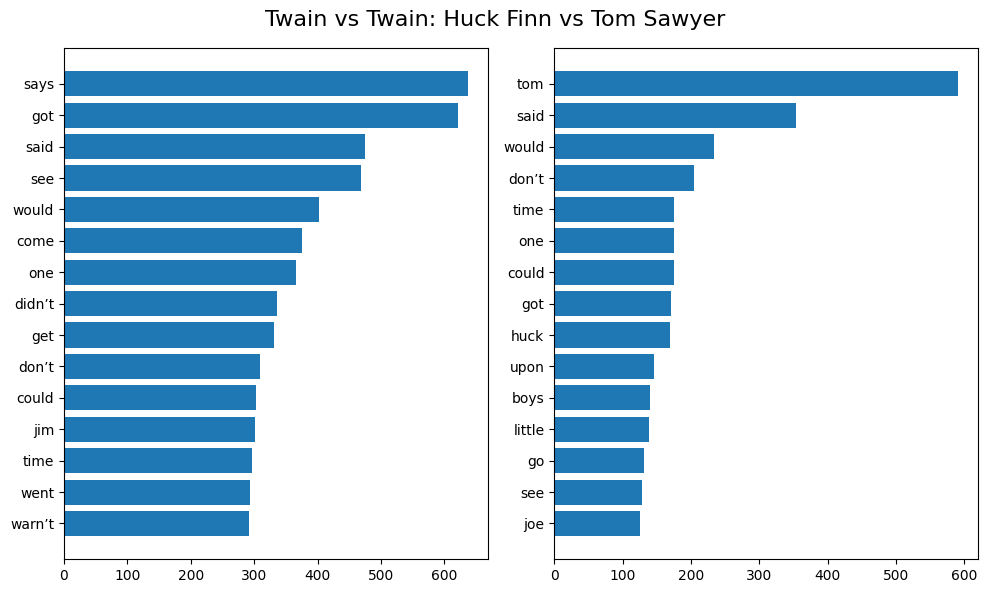

In [5]:
plot_two_lists(top_huck, top_tom, 'Twain vs Twain: Huck Finn vs Tom Sawyer')

### Cross-author comparison: Twain vs Jack London

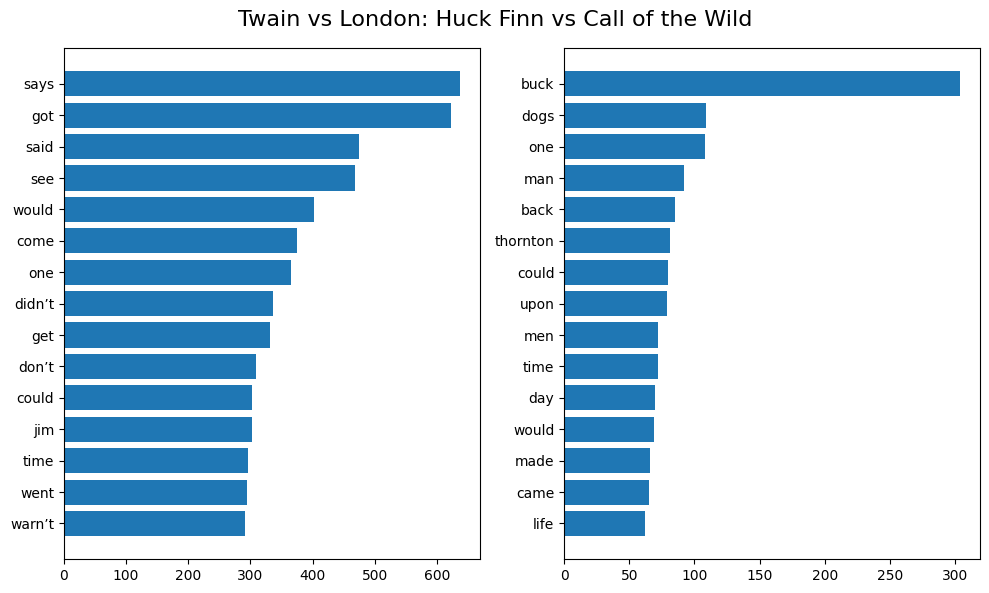

In [6]:
plot_two_lists(top_huck, top_wild, 'Twain vs London: Huck Finn vs Call of the Wild')

### Which words differ the most between texts?

Raw counts aren't fair to compare directly since the books are different lengths, so this compares *relative* frequency (share of total words) and ranks words by how far apart that share is between two texts.

In [7]:
def relative_freq(wf, total_words):
    return {w: c / total_words for w, c in wf.items()}

rel_huck = relative_freq(wf_huck, len(words_huck))
rel_tom  = relative_freq(wf_tom, len(words_tom))
rel_wild = relative_freq(wf_wild, len(words_wild))

def compare_relative(rel_a, rel_b, top=15):
    words = set(rel_a) | set(rel_b)
    diffs = [(w, rel_a.get(w, 0) - rel_b.get(w, 0)) for w in words]
    diffs.sort(key=lambda x: abs(x[1]), reverse=True)
    return diffs[:top]

print('Biggest differences: Huck Finn vs Tom Sawyer (same author)')
for w, d in compare_relative(rel_huck, rel_tom):
    print(f'{w}\t{d:+.5f}')

print('\nBiggest differences: Twain (Huck Finn) vs London (Call of the Wild)')
for w, d in compare_relative(rel_huck, rel_wild):
    print(f'{w}\t{d:+.5f}')

Biggest differences: Huck Finn vs Tom Sawyer (same author)
tom	-0.00651
says	+0.00552
got	+0.00318
jim	+0.00248
see	+0.00241
warn’t	+0.00240
didn’t	+0.00239
de	+0.00220
upon	-0.00205
en	+0.00203
come	+0.00184
huck	-0.00180
boys	-0.00175
joe	-0.00175
couldn’t	+0.00167

Biggest differences: Twain (Huck Finn) vs London (Call of the Wild)
buck	-0.00930
says	+0.00570
got	+0.00513
see	+0.00387
said	+0.00354
dogs	-0.00319
didn’t	+0.00302
come	+0.00284
don’t	+0.00269
jim	+0.00269
warn’t	+0.00263
thornton	-0.00255
ain’t	+0.00251
upon	-0.00247
right	+0.00210


### Extra credit: binomial distribution of a single word

Treat every word in the book as a trial, with "success" = the word matches our chosen word. The estimated probability p = count(word) / total_words. Comparing p across texts shows whether that word's usage rate really differs between books/authors, not just whether it shows up in a top-15 list.

In [8]:
word_choice = 'said'  # try swapping this for other words, e.g. 'now', 'never', 'boy'

def binomial_estimate(word, wds):
    n = len(wds)
    k = wds.count(word)
    p = k / n
    return p, k, n

for name, wds in [('Huck Finn', words_huck), ('Tom Sawyer', words_tom), ('Call of the Wild', words_wild)]:
    p, k, n = binomial_estimate(word_choice, wds)
    print(f"P('{word_choice}') in {name}: {p:.5f}  ({k} / {n})")

P('said') in Huck Finn: 0.00427  (474 / 111075)
P('said') in Tom Sawyer: 0.00499  (353 / 70785)
P('said') in Call of the Wild: 0.00072  (23 / 31823)


## Presentation Notes

*(Fill in after running the analysis above -- this is what gets turned into slides for the group presentation.)*

### What is the question?


### What was the approach?


### What problems did I encounter?


### What results did I get?


### What new ideas did this generate?



In [9]:
import requests, re, nltk
#In case your text is not on Project Gutenberg but at some other URL
#http://www.fullbooks.com/Our-World-or-The-Slaveholders-Daughter2.html
# that contains 12 parts
t = ""
for i in range(2,13):
  r = requests .get('http://www.fullbooks.com/Our-World-or-The-Slaveholders-Daughter' + str(i) + '.html')
  t = t + r.text

In [10]:
len(t)

1323653